# Racetrack Resonator -- Meep Baseline, Coupling-Length Search, and Design Selection

This is the fifth component in the toolkit: a single-bus (all-pass) **racetrack**
resonator -- a ring whose coupling section is a straight waveguide run rather than a
single point of closest approach. Like the earlier notebooks, this one is an
educational/validation record, not just a script -- work through it step by step,
and stop at the marked checkpoints.

## 1. Why a racetrack, and not a plain ring

Coupling strength between a bus and a ring can be controlled two ways: shrinking the
bus-ring **gap**, or lengthening the **straight coupling section** (a "racetrack").
This notebook uses the racetrack approach: the gap stays fixed at a comfortable,
easily-resolved **200nm**, and `coupling_length_um` -- the length of the straight
segment where the racetrack runs parallel to the bus -- is the coupling-strength
knob instead. Longer interaction length buys stronger coupling exactly like a
smaller gap would, without ever needing sub-wavelength resolution to resolve the
gap itself, and without forcing ring size and simulation-domain size to trade off
against each other.

### What a racetrack resonator is

A **racetrack** is two half-circles (radius `radius_um`, to the waveguide centerline)
joined by two straight segments (length `coupling_length_um`) -- a "stadium" shape. A
**bus waveguide** runs straight past the racetrack's *top* straight segment, separated
by a small, fixed gap; its evanescent field (the exponentially-decaying tail that
extends slightly beyond a guided mode's core) overlaps the racetrack across that gap --
**evanescent coupling**: a small, controllable fraction of the bus power leaks into the
racetrack on every pass, and an equal fraction leaks back out.

Once light is coupled into the racetrack, it circulates around the loop. The
racetrack's optical path length is now
$$L = 2\pi R + 2 L_c$$
(both straight segments contribute, even though only the one nearest the bus actually
couples to anything) -- one extra term over a plain ring's $L=2\pi R$. For most
wavelengths, light that has gone around once arrives back at the coupling point out of
step with light still arriving fresh from the bus, and the two interfere
**destructively**. But at specific wavelengths, the round-trip phase is a whole number
of cycles, the circulating light interferes **constructively** with itself, and builds
up to a much larger intensity inside the racetrack -- a **resonance**:
$$m\,\lambda_{res} = n_{eff}\, L \qquad (m = 1, 2, 3, \dots)$$
At resonance, the built-up circulating field re-couples back out to the bus mostly out
of phase with the light that never coupled in at all -- the two partially cancel,
producing a transmission dip whose depth depends on how closely the coupled-out power
matches the racetrack's own intrinsic loss (**critical coupling**, Section 10).

**Do not use "Run All."** Work through the notebook step by step, and stop at the two
marked checkpoints to actually look at the plots before continuing.


## 2. User parameters

Same units and material convention as `01_waveguide_baseline.ipynb`: lengths in
micrometers, silicon core / silicon dioxide cladding.

In [1]:
import inspect

import numpy as np
import matplotlib.pyplot as plt
import gdsfactory as gf

from pic_toolkit.meep_sim import racetrack
from pic_toolkit import checks, viz, sparams, design_points, sweep, style

style.apply_style()  # shared color palette + plot style for every notebook in this toolkit
%matplotlib inline

# ============================================================
# USER PARAMETERS
# ============================================================
params = dict(racetrack.DEFAULT_PARAMS)  # everything below reads from/derives off this dict
params


{'radius_um': 5.0,
 'gap_um': 0.2,
 'coupling_length_um': 3.0,
 'wg_width_um': 0.5,
 'wg_height_um': 0.22,
 'core_index': 2.7,
 'clad_index': 1.44,
 'ring_conductivity': 0.001,
 'wl_min_um': 1.3,
 'wl_max_um': 1.4,
 'n_freq': 301,
 'resolution': 25,
 'dpml_um': 1.0,
 'margin_um': 0.5,
 'dft_decay_tol': 0.001,
 'min_sim_time': 7000,
 'max_sim_time': 25000}

What each parameter means physically:

- **`radius_um`** -- half-circle (centerline) radius, kept at a realistic 5um.
  **Not swept in this notebook** -- `coupling_length_um` is the coupling-strength
  knob here, not the radius.
- **`gap_um`** -- bus-racetrack separation, **fixed at 200nm**, comfortably
  resolved by the grid. Coupling strength is instead controlled by
  `coupling_length_um` (Section 1 explains why).
- **`coupling_length_um`** -- length of the straight racetrack segment running
  parallel to the bus, and the primary knob varied in this notebook. Set here to
  ~3um as the Sections 3-8 baseline; Section 9 sweeps around it and Section 10
  selects the design.
- **`ring_conductivity`** -- a small electric conductivity (Meep `D_conductivity`)
  applied only to the racetrack's core material (the bus stays lossless), standing
  in for a real fabricated waveguide's propagation loss. Without some intrinsic
  loss channel there is nothing for the coupling to be "critical" against.
- **`wg_width_um`** -- waveguide width, same convention as every other component,
  used for both the bus and the racetrack.
- **`wg_height_um`** -- vertical thickness of the real 3D device this 2D model
  approximates. Not used by the simulation -- carried as metadata only.
- **`wl_min_um` / `wl_max_um` / `n_freq`** -- wavelength sweep range (O-band,
  1300-1400nm) and resolution. `n_freq=301`: this resonator's dips are only a
  few nm wide, so a denser grid than most components is needed to resolve them.
- **`resolution`** -- pixels/um, 25 -- still resolves the 200nm gap with 5 grid
  points; the main cost driver here is `min_sim_time` below, not spatial
  resolution.
- **`dft_decay_tol` / `min_sim_time` / `max_sim_time`** -- FDTD convergence
  controls for `mp.stop_when_dft_decayed()`. `min_sim_time` is an explicit floor:
  a longer coupling length couples into a higher-loaded-Q resonance whose
  ring-down decays slowly, and the default "has the change between checks
  plateaued" criterion can register as converged before the field has actually
  settled.


## 3. Build geometry

The bus and ring are built as TWO SEPARATE gdsfactory `Component`s (not merged into
one) -- the ring needs a lossy `ring_core` material (`D_conductivity=
ring_conductivity`) while the bus stays lossless, and `gds_import.py`'s
`gds_component_to_prisms()` only accepts one `material=` per call. The ring itself is
a single CLOSED gdsfactory `Path` (straight -> 180-degree arc -> straight -> 180-degree
arc, back to the start), extruded to `wg_width_um` -- the extruded closed loop is
already hollow (KLayout represents it as one self-touching "keyhole" polygon rather
than a polygon-with-holes structure, but the interior is confirmed correctly
cladding-index when rendered -- `gds_import.py` needed no changes to handle this).

(The earlier native-Meep-only construction this notebook used before the GDSFactory
migration is no longer shown here; `racetrack.py`'s `build_geometry()` function and
`use_native_geometry` flag remain in the module as reference code for anyone comparing
the two approaches directly in a REPL.)


In [2]:
print(inspect.getsource(racetrack._ring_gf_component))

def _ring_gf_component(params: dict):
    """The racetrack ring as ONE closed-loop gdsfactory Path (straight ->
    180-degree arc -> straight -> 180-degree arc, back to the start),
    extruded to wg_width_um -- a single annular Component, unlike
    build_geometry's native outer+inner stadium-carving pair. KLayout
    represents the resulting annulus as one self-touching "keyhole" simple
    polygon (`poly.holes()` reports 0), NOT a polygon-with-holes structure --
    confirmed empirically (direct epsilon sampling through
    gds_import.get_permittivity_map) that the interior is correctly hollow
    regardless, so gds_import.gds_component_to_prisms needs no changes.

    IMPORTANT: `gf.path.straight(length=0)` is NOT a geometric no-op -- at
    coupling_length_um=0 it corrupts the closed loop into a self-intersecting
    shape roughly 3.7x too wide (confirmed empirically: bbox width ~38.8um
    instead of the correct ~10.5um at radius_um=5). The `Lc > 0` branch below
    must omit th

In [3]:
print(inspect.getsource(racetrack.build_gf_component))
print(inspect.getsource(racetrack.build_geometry_from_gds))

def build_gf_component(params: dict) -> tuple:
    """Returns (bus, ring): two SEPARATE gdsfactory Components in the shared
    _compute_domain() coordinate frame. Kept separate (not merged into one
    Component) because they need DIFFERENT Meep materials once converted --
    plain `core` for the bus vs. lossy `ring_core` (D_conductivity=
    ring_conductivity) for the ring -- see build_geometry_from_gds."""
    return _bus_gf_component(params), _ring_gf_component(params)

def build_geometry_from_gds(params: dict) -> list:
    """Meep geometry sourced from build_gf_component via gds_import -- the
    default simulation path (see use_native_geometry flags below). Simpler
    than native build_geometry: the ring's closed-loop Path extrusion is
    already hollow, so no separate outer-stadium/inner-stadium carving pair
    is needed."""
    core = mp.Medium(index=params["core_index"])
    ring_core = mp.Medium(index=params["core_index"], D_conductivity=params["ring_conductivity"])
    b

**Why the ring Component has no ports**: it's a CLOSED loop -- its start and end point
are the same coincident point (the seam where the path closes). There is no physically
meaningful port on a closed ring, so `_ring_gf_component()` deliberately does not call
`add_ports()`. Only the bus Component has ports (`o1`/`o2`).

bus bbox: (-10.25,5.1;10.25,5.6)  ports: {'o1': ((-10.25, 5.3500000000000005), 180.0), 'o2': ((10.25, 5.3500000000000005), 0.0)}
ring bbox: (-6.748,-5.6;6.748,4.9)  (no ports -- closed loop, see markdown above)


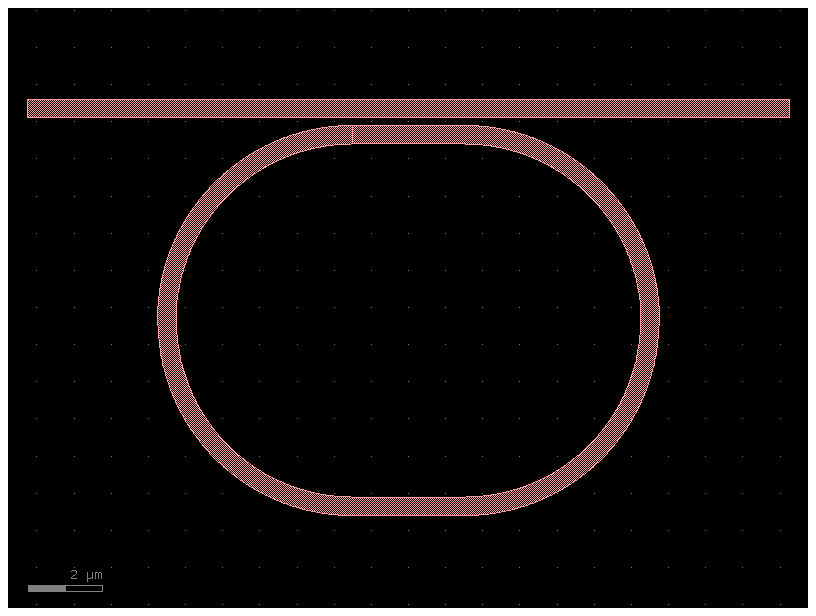

In [4]:
# Build both parts of the device as gdsfactory Components (kept separate --
# see the markdown above for why), then print their bounding boxes/ports so we
# can sanity-check sizes before rendering or simulating anything.
bus_gf, ring_gf = racetrack.build_gf_component(params)
print("bus bbox:", bus_gf.dbbox(), " ports:", {p.name: (p.dcenter, p.orientation) for p in bus_gf.ports})
print("ring bbox:", ring_gf.dbbox(), " (no ports -- closed loop, see markdown above)")

# Combine both Components into one throwaway Component purely for this plot --
# this is what the actual fabricated layout looks like (bus straight + racetrack
# ring, separated by the coupling gap).
combined = gf.Component()
combined.add_ref(bus_gf)
combined.add_ref(ring_gf)
fig = combined.plot()
plt.show()


## 4. Permittivity map

Built WITHOUT running any FDTD timestepping, exactly as in every other component --
the usual baseline-vs-degenerate-ring comparison, shown using the GDSFactory-derived
geometry (Section 3), since that's what `coupling_length_um=0` will actually exercise
going forward.


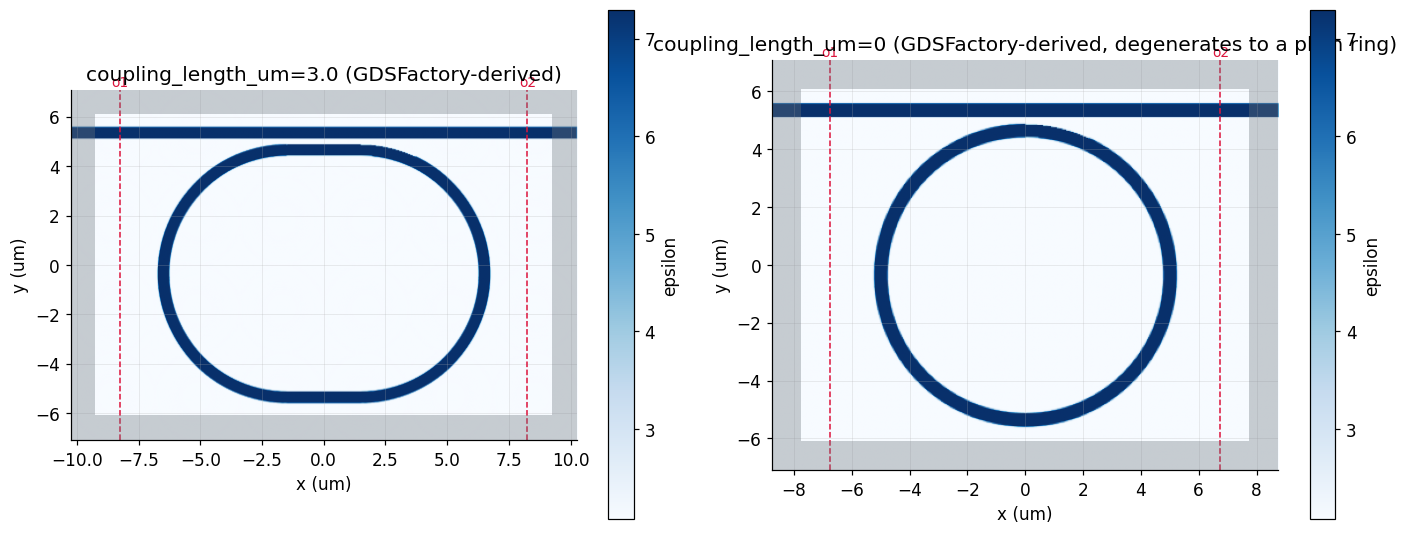

In [5]:
# Two side-by-side permittivity maps, computed WITHOUT running any FDTD
# timestepping (cheap): the actual device (left) and the coupling_length_um=0
# degenerate case (right), which collapses the racetrack into a plain circular
# ring -- a useful visual sanity check that the stadium shape is built correctly.
def _ports_for(p):
    dom = racetrack._compute_domain(p)
    return [
        (-dom["port_offset"], dom["bus_y"], "o1", "v"),
        (dom["port_offset"], dom["bus_y"], "o2", "v"),
    ]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

perm_map = racetrack.get_permittivity_map(params)  # use_native_geometry=False by default -- GDSFactory-derived
viz.plot_permittivity(perm_map.eps, perm_map.extent_um, ax=axes[0],
                       ports=_ports_for(params), pml_um=params["dpml_um"])
axes[0].set_title(f"coupling_length_um={params['coupling_length_um']} (GDSFactory-derived)")

params0 = {**params, "coupling_length_um": 0.0}
perm_map0 = racetrack.get_permittivity_map(params0)
viz.plot_permittivity(perm_map0.eps, perm_map0.extent_um, ax=axes[1],
                       ports=_ports_for(params0), pml_um=params0["dpml_um"])
axes[1].set_title("coupling_length_um=0 (GDSFactory-derived, degenerates to a plain ring)")

fig.tight_layout()
plt.show()


> **STOP -- INSPECT THE PERMITTIVITY MAP BEFORE RUNNING FDTD.**
>
> Check, before paying for an expensive simulation:
> - **Racetrack shape**: a stadium (two half-circles + two straight runs) in the left
>   panel, collapsing to a plain circle in the right panel.
> - **Bus-racetrack gap**: is there a clear, uniform 200nm gap between the bus and the
>   nearest point of the racetrack's top straight segment?
> - **Waveguide width**: are the bus and racetrack cross-sections both `wg_width_um`
>   wide?
> - **Racetrack position**: is it centered horizontally under the bus?
> - **Domain size / PML placement**: visible clearance between the structure and the
>   domain edges, no overlap with PML.
> - **No unintended overlaps**: bus and racetrack should not touch or intersect.
>
> If anything looks wrong, fix `params` above and re-run from Section 3.


## 5. Baseline FDTD simulation

Same rigorous two-port philosophy as every other component: `simulate_baseline()`
excites from **each port independently** and measures the full 2x2 complex S-matrix
from genuinely independent data. It also runs one extra **reference simulation**
first, with the racetrack removed (bus only), to measure the true incident mode
amplitude -- necessary because a resonant structure can leave energy circulating long
after the source pulse itself has finished, contaminating self-normalization.

**Geometry source**: `simulate_baseline()` uses the GDSFactory-derived geometry
(Section 3) by default (`use_native_geometry=False`) -- including the bus-only
reference run, which sources its bus from the SAME `_bus_gf_component()` the with-ring
run uses, so both runs' bus discretization matches exactly (see `_reference_incident`'s
docstring for why a mismatch here would matter).

A source-bandwidth margin compensates for a Gaussian source's spectral power falling
off toward the edges of its own frequency window -- see
`racetrack._SOURCE_BANDWIDTH_MARGIN`.


In [6]:
# Full two-port characterization at the Section-2 baseline coupling_length_um --
# this runs the reference (bus-only) simulation plus both excitation directions
# under the hood (see the markdown above), so the full 2x2 S-matrix below is
# built from genuinely independent measurements, not assumed symmetry.
# Cache-or-run: if the Section-8 artifact already exists for exactly these
# parameters, it is reloaded instead of re-simulated (racetrack.load_or_simulate_baseline
# checks every recorded parameter and the wavelength grid before reusing it).
result = racetrack.load_or_simulate_baseline(params, "../data/sparams/racetrack/baseline/racetrack_baseline")
print(f"{len(result.wavelengths_um)} wavelength points, "
      f"{result.wavelengths_um.min():.4f}-{result.wavelengths_um.max():.4f} um")

loaded cached FDTD result: ../data/sparams/racetrack/baseline/racetrack_baseline
301 wavelength points, 1.3017-1.4020 um


## 6. S-parameters

The complete complex 2x2 S-matrix, exactly as in every other component -- not only
S21.

**Magnitude only, no phase plot.** This band (1.30-1.40um, 301 points) contains six resonances, spaced by the free spectral range $\mathrm{FSR} = \lambda^2/(n_g L) \approx 16$ nm ($n_g \approx 2.98$, $L = 37.4$ µm; measured below), each only a few nm wide. Near every resonance the phase genuinely sweeps by $\sim 2\pi$ -- real physics, and `np.unwrap` handles it correctly -- but that sweep spans only a handful of grid points here, so the correctly-unwrapped curve still looks like a staircase of jumps rather than a smooth ramp. That is a sampling-density limit of this baseline grid, not a bug, and resolving it would need many more wavelength points than this view is meant for. The magnitude plot below already shows every resonance clearly.


In [7]:
# Quick numeric sanity check before plotting: every |S|^2 should sit in [0, 1]
# (a passive device can't amplify) -- a full plot follows below.
for key in ["11", "12", "21", "22"]:
    s = result.s_matrix[key]
    print(f"S{key}: |S|^2 range [{np.min(np.abs(s)**2):.4f}, {np.max(np.abs(s)**2):.4f}]")


S11: |S|^2 range [0.0000, 0.0385]
S12: |S|^2 range [0.2996, 0.9992]
S21: |S|^2 range [0.2999, 0.9993]
S22: |S|^2 range [0.0001, 0.0380]


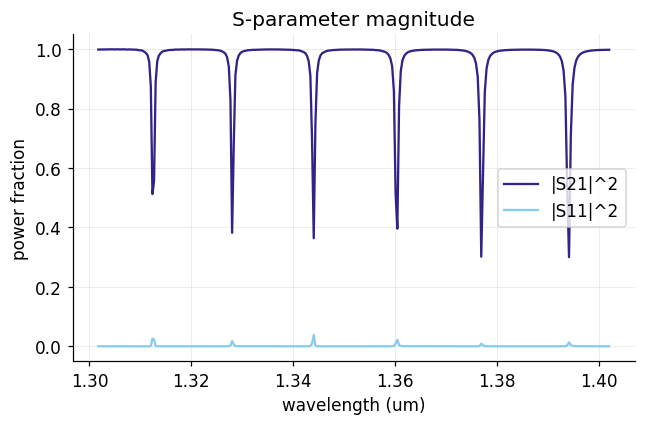

In [8]:
# Full-band magnitude for the transmitted (S21) and reflected (S11) ports --
# viz.plot_sparams applies this toolkit's shared color/style convention.
# show_phase=False: see the markdown above for why a phase-vs-wavelength plot
# is not useful at this resonance width/sampling density.
fig = viz.plot_sparams(result.wavelengths_um, result.s_matrix, pairs=("21", "11"), show_phase=False)
plt.show()


The dip is shallow at this scale -- zooming in on just the transmission trace
makes it clearly visible:

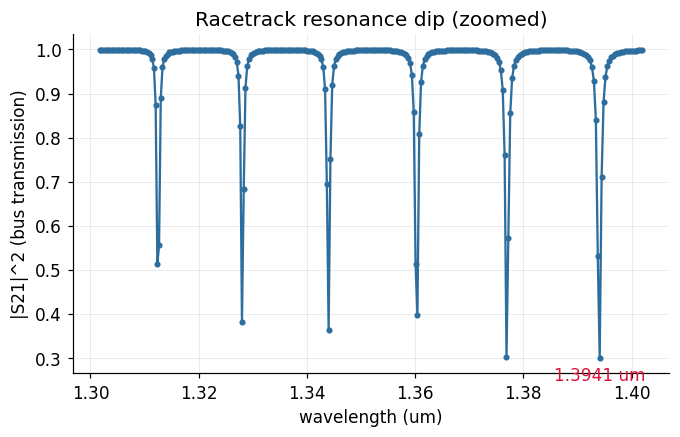

Resonance wavelength: 1.3941 um, on-resonance transmission 0.2999


In [9]:
# The resonance dip is only a few nm wide, so it's invisible at the full O-band
# scale above -- zoom in on |S21|^2 alone and mark exactly where the dip sits.
s21_power = np.abs(result.s_matrix["21"]) ** 2
dip_wl = result.wavelengths_um[np.argmin(s21_power)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(result.wavelengths_um, s21_power, "-o", markersize=3, color=style.COLOR_STEEL)
ax.annotate(f"{dip_wl:.4f} um", (dip_wl, s21_power.min()),
            textcoords="offset points", xytext=(0, -15), ha="center", color=style.COLOR_ANNOTATION)
ax.set_xlabel("wavelength (um)")
ax.set_ylabel("|S21|^2 (bus transmission)")
ax.set_title("Racetrack resonance dip (zoomed)")
plt.show()
print(f"Resonance wavelength: {dip_wl:.4f} um, on-resonance transmission {s21_power.min():.4f}")



### Group index from the free spectral range

The full-band spectrum above contains several resonances. Their spacing, the free
spectral range, measures the **group index** of the ring waveguide:

$$\mathrm{FSR} = \frac{\lambda^2}{n_g L}, \qquad n_g = \frac{\lambda_1 \lambda_2}{(\lambda_2 - \lambda_1)\,L}
\quad\text{for neighbouring resonances } \lambda_1, \lambda_2 .$$

This matters for every fit below. A resonance sits where the round-trip phase is
$2\pi m$, $\lambda_m = n_{eff} L / m$, so one resonance alone fixes only $n_{eff}L/m$:
the azimuthal order $m$ (here about 66) is not known, and neighbouring orders change
the inferred $n_{eff}$ by $\lambda/L \approx 0.035$. What sets the *shape* of a
resonance in wavelength is how fast the round-trip phase changes,
$d\phi/d\lambda = -2\pi n_g L/\lambda^2$. The fits in Sections 10 and 12 therefore
linearize the phase around each resonance with this measured $n_g$,
$\phi(\nu) = 2\pi (\nu - \nu_{res}) / \mathrm{FSR}_\nu$ with $\mathrm{FSR}_\nu = 1/(n_g L)$,
and do not fit $n_{eff}$ at all.


In [10]:

# Group index from the resonance spacing of the full-band baseline (Section 5).
from pic_toolkit import ring_fit
from pic_toolkit.slab_modes import group_index, n_eff_single

L_baseline = 2 * np.pi * params["radius_um"] + 2 * params["coupling_length_um"]
N_G, fsr_info = ring_fit.group_index_from_fsr(result.wavelengths_um, np.abs(result.s_matrix["21"]) ** 2, L_baseline)
grid_nm = fsr_info["grid_spacing_nm"]
print(f"resonances (um): {np.round(fsr_info['resonances_um'], 4)}")
print(f"FSR (nm):        {np.round(fsr_info['fsr_nm'], 2)}")
print(f"n_g = {N_G:.3f}  (median over {len(fsr_info['n_g_pairs'])} neighbouring pairs; the {grid_nm:.2f} nm "
      f"wavelength grid limits it to about +-{100 * grid_nm / np.mean(fsr_info['fsr_nm']):.0f} %)")
# Cross-check against the straight 2D waveguide from the 1D mode solver (same indices, 500 nm wide).
print(f"straight waveguide, slab solver: n_eff = {n_eff_single():.4f}, n_g = {group_index():.4f}")
print(f"azimuthal order near 1.344 um: m ~ n_eff L / lambda = "
      f"{n_eff_single() * L_baseline / fsr_info['resonances_um'][2]:.1f}")


resonances (um): [1.3124 1.328  1.344  1.3604 1.3769 1.3941]
FSR (nm):        [15.64 16.02 16.41 16.47 17.23]
n_g = 2.978  (median over 5 neighbouring pairs; the 0.33 nm wavelength grid limits it to about +-2 %)


straight waveguide, slab solver: n_eff = 2.4184, n_g = 2.9284


azimuthal order near 1.344 um: m ~ n_eff L / lambda = 67.3


## 7. Physics sanity checks

Same three checks as every other component -- energy conservation, reciprocity,
and passivity -- adapted for a resonant device. Near critical coupling, a ring is
*supposed* to absorb most of the input power exactly at resonance while staying
essentially lossless everywhere else, so one flat tolerance across the whole
spectrum would either miss a real bug off-resonance or wrongly flag the
resonance dip itself as broken. `racetrack.energy_conservation_check` applies a
**tight** lossless requirement off resonance and a **loose**, physicality-only
bound on resonance instead.

**Reflection appears only on resonance.** The bus runs straight through the PML at both
ends, so there is no facet; $|S_{11}|^2$ stays below 0.2 % off resonance and rises to
at most 3.9 % at the resonance dips. That is backscattering inside the ring: the
staircased circular sections couple the circulating mode weakly to the
counter-propagating one, and the resonance enhances it. Its phase depends on where the
standing wave falls on the grid, so $S_{11}$ and $S_{22}$ differ by up to 0.29 on
resonance (0.04 off resonance), which is why the $S_{11}=S_{22}$ sub-check uses a loose
tolerance; true reciprocity, $S_{12}=S_{21}$, stays within 0.03.


In [11]:
# Tolerances set from this device's measured validation residuals (with a
# resonator-specific energy check: tight off resonance, loose on resonance).
OFF_RESONANCE_TOL = 0.02   # off-resonance points must stay within 2% of lossless
MIN_DIP_DEPTH = 0.1        # a dip only counts as a genuine resonance (exempt from
                           # the tight off-resonance bound) if it's >=10% below the median
RECIPROCITY_TOL = 0.35     # loosened for this device's S11=S22 sub-check specifically
                           # (true reciprocity, S12=S21, stays small regardless)
PASSIVITY_TOL = 0.01

def racetrack_validate(result, **check_kwargs):
    """Composite validator for this component: the resonance-aware energy check
    (`racetrack.energy_conservation_check`, tight off-resonance / loose
    on-resonance) plus the still-generic reciprocity/passivity checks (neither
    has an "expected to be violated at resonance" exception, so the shared
    2-port versions are correct as-is). Same `validate_fn(result,
    **check_kwargs) -> dict` shape `sweep.grid_sweep` expects (Section 9), so
    this one function validates both the baseline below and every sweep point.
    """
    energy = racetrack.energy_conservation_check(
        result.s_matrix, result.wavelengths_um,
        off_resonance_tol=check_kwargs.get("off_resonance_tol", OFF_RESONANCE_TOL),
        min_dip_depth=check_kwargs.get("min_dip_depth", MIN_DIP_DEPTH),
        passivity_tol=check_kwargs.get("passivity_tol", PASSIVITY_TOL),
    )
    reciprocity = checks.reciprocity_check(result.s_matrix, tol=check_kwargs.get("reciprocity_tol", RECIPROCITY_TOL))
    passivity = checks.passivity_check(result.s_matrix, tol=check_kwargs.get("passivity_tol", PASSIVITY_TOL))
    return {
        "energy_conservation": energy,
        "reciprocity": reciprocity,
        "passivity": passivity,
        "passed": bool(energy["passed"] and reciprocity["passed"] and passivity["passed"]),
    }

# Run and print the composite check on the baseline result; stop immediately
# (via the assert) rather than saving or building on top of an invalid result.
validation = racetrack_validate(result)

import json
print(json.dumps(validation, indent=2))
assert validation["passed"], "Baseline failed sanity checks -- do not save or use this result."
print("\nBaseline validated.")


{
  "energy_conservation": {
    "port1": {
      "off_resonance_baseline": 0.9972073884909577,
      "n_off_resonance_points": 83,
      "n_resonance_points": 218,
      "off_resonance_deviation": 0.002465199990212774,
      "max_physicality_excess": 0.0,
      "passed": true
    },
    "port2": {
      "off_resonance_baseline": 0.9971223061812046,
      "n_off_resonance_points": 77,
      "n_resonance_points": 224,
      "off_resonance_deviation": 0.002547219723918026,
      "max_physicality_excess": 0.0,
      "passed": true
    },
    "off_resonance_tol": 0.02,
    "min_dip_depth": 0.1,
    "passivity_tol": 0.01,
    "passed": true
  },
  "reciprocity": {
    "max_diff_s12_s21": 0.027853213182572046,
    "max_diff_s11_s22": 0.29373560188175335,
    "max_diff": 0.29373560188175335,
    "tolerance": 0.35,
    "passed": true
  },
  "passivity": {
    "max_magnitude": 0.9996308429046289,
    "tolerance": 0.01,
    "passed": true
  },
  "passed": true
}

Baseline validated.


## 8. Save baseline artifact

Same format as every other component: `.npz` (numeric arrays) + `.json` (metadata)
sidecar pair, via the shared `sparams.py`.


In [12]:
# Standard .npz (numeric arrays) + .json (metadata) artifact pair, same
# format every other component uses -- this is the raw, validated FDTD result,
# independent of any later fitting.
artifact_stem = "../data/sparams/racetrack/baseline/racetrack_baseline"

metadata = {
    "component": "racetrack",
    "geometry_params": {
        "radius_um": result.sim_params["radius_um"],
        "gap_um": result.sim_params["gap_um"],
        "coupling_length_um": result.sim_params["coupling_length_um"],
        "wg_width_um": result.sim_params["wg_width_um"],
        "wg_height_um": result.sim_params["wg_height_um"],
    },
    "material_params": {
        "core_index": result.sim_params["core_index"],
        "clad_index": result.sim_params["clad_index"],
        "ring_conductivity": result.sim_params["ring_conductivity"],
    },
    "polarization": "TE (Hz out-of-plane -- confirmed dominant field component for this "
                     "device's eig_band=1 mode, see Section 6)",
    "meep_resolution": result.sim_params["resolution"],
    "simulation_params": {
        k: result.sim_params[k]
        for k in ["wl_min_um", "wl_max_um", "n_freq", "dpml_um", "margin_um",
                  "dft_decay_tol", "min_sim_time", "max_sim_time"]
    },
    "meep_version": result.sim_params["meep_version"],
    "python_version": result.sim_params["python_version"],
    "creation_date": result.sim_params["creation_date"],
    "validation": validation,
}

sparams.save_artifact(
    artifact_stem, result.wavelengths_um, result.freqs,
    result.s_matrix, result.port_names, metadata,
)
print(f"Saved artifact: {artifact_stem}.npz / .json")


Saved artifact: ../data/sparams/racetrack/baseline/racetrack_baseline.npz / .json


---

## 9. Coupling-length sweep (through critical coupling)

**The baseline above has been inspected and validated -- only now do we sweep.**
`sweep.grid_sweep()` runs the same baseline simulation once per coupling length,
saving one artifact (npz+json) per point under `../data/sparams/racetrack/sweep/`.
`radius_um` and `gap_um` stay fixed at their Section 2 values -- `coupling_length_um`
is the only thing varied. Each point is loaded from its saved artifact if one exists
for exactly these parameters (`racetrack.load_or_simulate_baseline`), so re-running
this cell does not repeat the FDTD runs.

**Sweep grid: `[2.0, 2.5, 3.0, 3.5, 4.0, 6.0, 8.0, 9.0, 10.0, 11.0, 12.0]` um.**
A longer coupling section gives stronger bus-ring coupling. The short sections
(2.0-4.0 um) are all under-coupled; for this ring's loss, critical coupling needs about
three times their cross-coupling, which the 6-12 um points reach, in 1 um steps around
the turnover (Section 10). The ring length $L = 2\pi R + 2L_c$ grows from 35 to 55 um over
the sweep, so the free spectral range shrinks from about 16 to 10 nm.

**Narrowband, higher-resolution wavelength grid for THIS sweep only.** The resonance
dips are much narrower than the full O-band grid (`n_freq=301`) can resolve, so this
sweep analyzes `1.3050-1.3200um` (15 nm, at least one free spectral range at every
length) with `n_freq=402`. The override is a local `dict(params, ...)` copy passed to
`grid_sweep`; it does not touch `params` (Section 2) or `racetrack.DEFAULT_PARAMS`.

**Same tolerances as the baseline, not loosened.** `racetrack.energy_conservation_check`
re-detects each configuration's own resonance dips (including one clipped by the window
edge), so Section 7's validator applies unchanged at every swept point; the manifest
records `validation_passed` per point. Points that fail stay in the sweep and are marked
in Section 10; they are not used for the selection.

In [13]:
# Same tolerances as the Section-8 baseline (not loosened) -- the resonance-aware
# energy check already adapts itself per point.
SWEEP_CHECK_KWARGS = {
    "off_resonance_tol": OFF_RESONANCE_TOL, "min_dip_depth": MIN_DIP_DEPTH,
    "reciprocity_tol": RECIPROCITY_TOL, "passivity_tol": PASSIVITY_TOL,
}

# 2.0-4.0 um: under-coupled; 6-12 um: up to and just past critical coupling, in 1 um
# steps around it.
COUPLING_LENGTH_SWEEP_UM = [2.0, 2.5, 3.0, 3.5, 4.0, 6.0, 8.0, 9.0, 10.0, 11.0, 12.0]

# THIS sweep only: a 15 nm window around one resonance with a dense grid (see markdown).
sweep_params = dict(params, wl_min_um=1.3050, wl_max_um=1.3200, n_freq=402)
SWEEP_DIR = "../data/sparams/racetrack/sweep"


def simulate_or_load(run_params):
    # Reuse the saved artifact of this exact point if it exists (no FDTD); otherwise simulate.
    stem = f"{SWEEP_DIR}/racetrack_coupling_length{run_params['coupling_length_um']}"
    return racetrack.load_or_simulate_baseline(run_params, stem)


coupling_rows = sweep.grid_sweep(
    simulate_fn=simulate_or_load,
    base_params=sweep_params,
    param_grid={"coupling_length_um": COUPLING_LENGTH_SWEEP_UM},
    artifact_dir=SWEEP_DIR,
    component_name="racetrack",
    check_kwargs=SWEEP_CHECK_KWARGS,
    validate_fn=racetrack_validate,  # this component's resonance-aware validator (Section 7)
)
n_passed = sum(row["validation_passed"] for row in coupling_rows)
print(f"coupling-length sweep: {n_passed}/{len(coupling_rows)} points within tolerance")

manifest_path = f"{SWEEP_DIR}/manifest.csv"
sweep.save_manifest(coupling_rows, manifest_path)
print(f"Saved manifest to {manifest_path}")

[1/11  9%] running racetrack (coupling_length_um=2.0) ...


loaded cached FDTD result: ../data/sparams/racetrack/sweep/racetrack_coupling_length2.0
[2/11  18%] running racetrack (coupling_length_um=2.5) ...


loaded cached FDTD result: ../data/sparams/racetrack/sweep/racetrack_coupling_length2.5
[3/11  27%] running racetrack (coupling_length_um=3.0) ...


loaded cached FDTD result: ../data/sparams/racetrack/sweep/racetrack_coupling_length3.0
[4/11  36%] running racetrack (coupling_length_um=3.5) ...


loaded cached FDTD result: ../data/sparams/racetrack/sweep/racetrack_coupling_length3.5
[5/11  45%] running racetrack (coupling_length_um=4.0) ...


...

loaded cached FDTD result: ../data/sparams/racetrack/sweep/racetrack_coupling_length8.0
[8/11  72%] running racetrack (coupling_length_um=9.0) ...


loaded cached FDTD result: ../data/sparams/racetrack/sweep/racetrack_coupling_length9.0
[9/11  81%] running racetrack (coupling_length_um=10.0) ...


loaded cached FDTD result: ../data/sparams/racetrack/sweep/racetrack_coupling_length10.0
[10/11  90%] running racetrack (coupling_length_um=11.0) ...


loaded cached FDTD result: ../data/sparams/racetrack/sweep/racetrack_coupling_length11.0
[11/11  100%] running racetrack (coupling_length_um=12.0) ...


loaded cached FDTD result: ../data/sparams/racetrack/sweep/racetrack_coupling_length12.0
coupling-length sweep: 9/11 points within tolerance
Saved manifest to ../data/sparams/racetrack/sweep/manifest.csv


## 10. Coupling regime and design selection

**Model.** For a bus-ring coupler with field self-coupling $t$ and cross-coupling
$\kappa$ ($t^2+\kappa^2=1$), single-pass field transmission $a$ ($a^2 = e^{-\alpha L}$,
$\alpha$ = power attenuation per um) and round-trip phase $\phi$, the all-pass
transmission is (Yariv, Electron. Lett. 36, 321 (2000))
$$S_{21} = \frac{t - a\,e^{j\phi}}{1 - t\,a\,e^{j\phi}}, \qquad
T_{min} = \frac{(a-t)^2}{(1-at)^2}, \qquad
\Delta\lambda_{FWHM} = \frac{(1-at)\,\lambda^2}{\pi n_g L \sqrt{at}} .$$
Each swept resonance is fitted with $\phi$ linearized by the measured group index
(Section 6), so the free parameters are $t$, $a$, the resonance frequency and a
near-unity scale for the off-resonance insertion loss.

**Two branches, one physical.** $T(\phi)$ is symmetric in $t \leftrightarrow a$: the same
power spectrum fits "weak coupling, high loss" ($t > a$, **under-coupled**) and
"strong coupling, low loss" ($t < a$, **over-coupled**) equally well (McKinnon et al.,
Opt. Express 17, 18971 (2009)). Both branches are fitted, and the physical one is
chosen from two independent pieces of evidence:
- **phase** -- across an under-coupled resonance the phase of $S_{21}$ swings by much
  less than $\pi$ and returns; across an over-coupled one it advances by $2\pi$
  (Heebner et al., IEEE JQE 40, 726 (2004));
- **loss floor** -- the ring's conductivity alone causes an absorption
  $\alpha_{abs}$ (perturbation theory with the slab mode solver); a branch whose
  fitted $\alpha$ is below $\alpha_{abs}$ is unphysical.

**Critical coupling** is the amplitude condition $t = a$ ($T_{min} = 0$); it is a
different condition from resonance ($\phi = 2\pi m$). For the fitted loss it requires
$\kappa^2 = 1 - a^2$ (column `crit k^2` below). Exactly at $t = a$ the two branches
coincide and the phase jumps by $\pi$ where the transmitted field passes through zero,
so near critical coupling the measured phase swing is close to $\pi$ and the branch
label stops mattering.

**Selection.** The design point is the validated sweep point with the deepest dip
(closest to $t = a$). One clearly under-coupled point ($L_c$ = 4 um) is kept alongside it
for the phase comparison below and the field comparison in Section 11.

In [14]:
# Loss floor set by the ring material alone: Meep's D_conductivity gives
# eps'' = eps * sigma / omega; the mode sees dn_eff/dn_core of the core's n''.
WL_SWEEP_CENTER = (sweep_params["wl_min_um"] + sweep_params["wl_max_um"]) / 2
ALPHA_FLOOR = ring_fit.absorption_floor(params["ring_conductivity"], WL_SWEEP_CENTER)
print(f"absorption floor alpha_abs = {ALPHA_FLOOR:.3e} 1/um ({ALPHA_FLOOR * 1e4 * 4.343:.0f} dB/cm) "
      f"at {WL_SWEEP_CENTER} um")

absorption floor alpha_abs = 2.774e-03 1/um (120 dB/cm) at 1.3125 um


Lc=2.0: measured phase swing 0.42 rad < pi -> under-coupled; over-coupled branch alpha 6.68e-04 < absorption floor 2.77e-03 /um (unphysical)
Lc=2.5: measured phase swing 0.33 rad < pi -> under-coupled; over-coupled branch alpha 8.45e-04 < absorption floor 2.77e-03 /um (unphysical)
Lc=3.0: measured phase swing 0.48 rad < pi -> under-coupled; over-coupled branch alpha 1.00e-03 < absorption floor 2.77e-03 /um (unphysical)
Lc=3.5: measured phase swing 0.61 rad < pi -> under-coupled; over-coupled branch alpha 1.10e-03 < absorption floor 2.77e-03 /um (unphysical)
Lc=4.0: measured phase swing 0.64 rad < pi -> under-coupled; over-coupled branch alpha 1.26e-03 < absorption floor 2.77e-03 /um (unphysical)
Lc=6.0: measured phase swing 1.12 rad < pi -> under-coupled; over-coupled branch alpha 2.00e-03 < absorption floor 2.77e-03 /um (unphysical)
Lc=8.0: measured phase swing 1.55 rad < pi -> under-coupled
Lc=9.0: measured phase swing 1.53 rad < pi -> under-coupled
Lc=10.0: measured phase swing 4.85

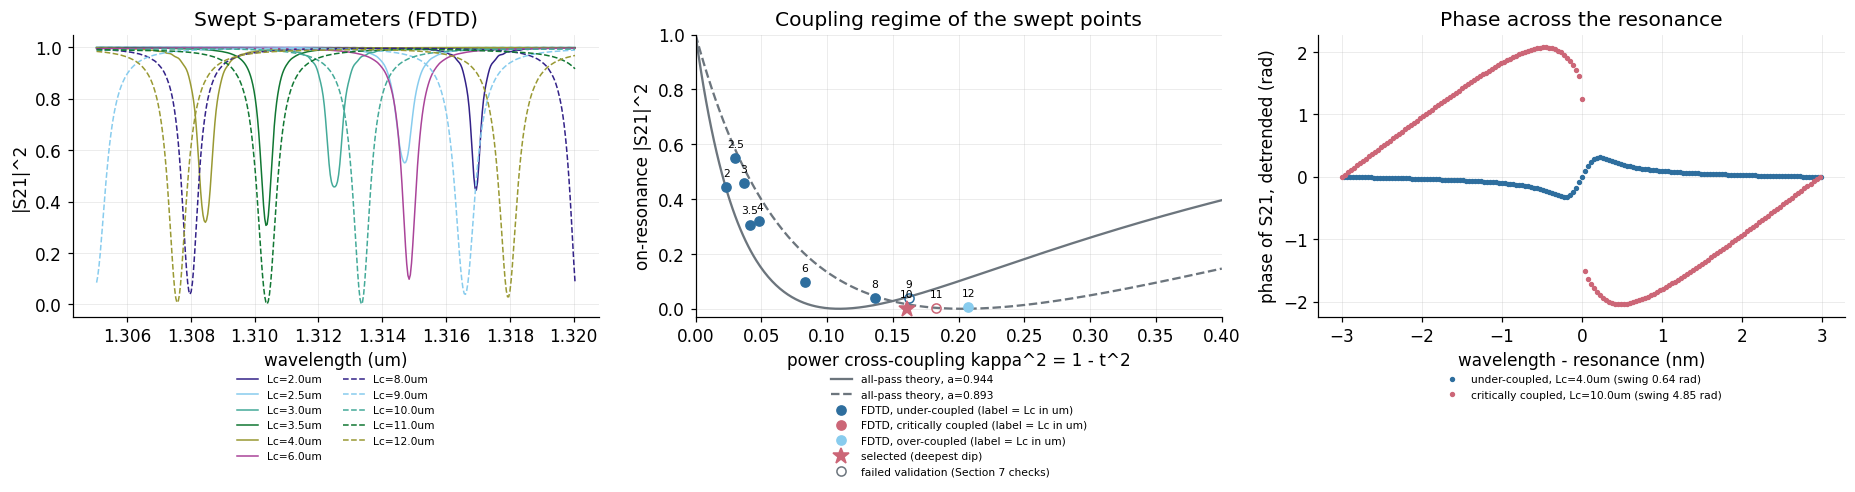

Saved design point: ../data/design_points/racetrack.yaml


In [15]:
# Fit every swept resonance (both t<->a branches, phase slope from N_G) and choose the
# physical branch from the measured phase swing and the absorption floor.
cmt_by_length = {}
artifacts_by_length = {}
for lc in COUPLING_LENGTH_SWEEP_UM:
    a = sparams.load_artifact(f"{SWEEP_DIR}/racetrack_coupling_length{lc}")
    artifacts_by_length[lc] = a
    L_lc = 2 * np.pi * params["radius_um"] + 2 * lc
    fit = ring_fit.fit_all_pass(a.wavelengths_um, a.s_matrix["21"], L_lc, N_G)
    regime, chosen, reason = ring_fit.choose_branch(fit, ALPHA_FLOOR)
    cmt_by_length[lc] = {**fit, "regime": regime, "chosen": chosen, "reason": reason,
                         "kappa2_crit": ring_fit.critical_kappa2(chosen["a"])}
    print(f"Lc={lc}: {reason}")

print(f"\n{'Lc':>5} {'T_min':>6} {'kappa^2':>8} {'crit k^2':>8} {'t':>7} {'a':>7} {'alpha(1/um)':>11} "
      f"{'FWHM meas/formula (nm)':>23} {'Q_L':>6} {'Q_i':>6}  regime")
for lc in COUPLING_LENGTH_SWEEP_UM:
    f, c = cmt_by_length[lc], cmt_by_length[lc]["chosen"]
    print(f"{lc:5.1f} {f['T_min']:6.3f} {c['kappa2']:8.4f} {f['kappa2_crit']:8.4f} {c['t']:7.4f} {c['a']:7.4f} "
          f"{c['alpha_per_um']:11.2e} {f['fwhm_nm']:11.3f} / {c['fwhm_formula_nm']:.3f} {f['Q_L']:6.0f} "
          f"{c['Q_i']:6.0f}  {c['regime']}"
          f"{'' if artifacts_by_length[lc].metadata['validation']['passed'] else '  (FAILED validation)'}")

passed_lengths = [lc for lc in COUPLING_LENGTH_SWEEP_UM if artifacts_by_length[lc].metadata["validation"]["passed"]]

# --- Human selection: edit these after reading the table/plots ---
# Critical coupling = the deepest swept dip (t closest to a); one clearly under-coupled
# point is kept as contrast for the field and phase comparison.
SELECTED_COUPLING_LENGTH_UM = min(passed_lengths, key=lambda lc: cmt_by_length[lc]["T_min"])
UNDER_COUPLING_LENGTH_UM = 4.0
REGIME_LENGTHS = {"under-coupled": UNDER_COUPLING_LENGTH_UM, "critically coupled": SELECTED_COUPLING_LENGTH_UM}
print(f"\nselected (critical coupling): Lc={SELECTED_COUPLING_LENGTH_UM} um")

# Where the swept points sit relative to critical coupling (t = a). The loss per round trip
# grows with L = 2*pi*R + 2*Lc, so the theory is drawn for the fitted a of the shortest and
# the longest swept ring (band), each point colored by its regime.
fitted_a = [cmt_by_length[lc]["chosen"]["a"] for lc in COUPLING_LENGTH_SWEEP_UM]
k2 = np.linspace(0, 0.4, 400)
t_curve = np.sqrt(1 - k2)
regime_color = {"under-coupled": style.COLOR_STEEL, "critically coupled": style.COLOR_ROSE,
                "over-coupled": style.COLOR_CYCLE[1]}
fig, (ax_spectra, ax_regime, ax_phase) = plt.subplots(1, 3, figsize=(17, 4.8))
for j, lc in enumerate(COUPLING_LENGTH_SWEEP_UM):
    a = artifacts_by_length[lc]
    order = np.argsort(a.wavelengths_um)
    # solid for the first pass through the color cycle, dashed once it repeats
    ax_spectra.plot(a.wavelengths_um[order], np.abs(a.s_matrix["21"][order]) ** 2,
                    color=style.COLOR_CYCLE[j % len(style.COLOR_CYCLE)],
                    ls="-" if j < len(style.COLOR_CYCLE) else "--", lw=1, label=f"Lc={lc}um")
for a_edge, ls in ((max(fitted_a), "-"), (min(fitted_a), "--")):
    ax_regime.plot(k2, ((t_curve - a_edge) / (1 - t_curve * a_edge)) ** 2, ls, color=style.COLOR_REFERENCE,
                   label=f"all-pass theory, a={a_edge:.3f}")
for lc in COUPLING_LENGTH_SWEEP_UM:
    c = cmt_by_length[lc]["chosen"]
    marker = "*" if lc == SELECTED_COUPLING_LENGTH_UM else "o"
    color = style.COLOR_ROSE if marker == "*" else regime_color[c["regime"]]
    ax_regime.plot(c["kappa2"], cmt_by_length[lc]["T_min"], marker, ms=11 if marker == "*" else 6, color=color,
                   markerfacecolor=color if lc in passed_lengths else "none")  # hollow: failed validation
    ax_regime.annotate(f"{lc:g}", (c["kappa2"], cmt_by_length[lc]["T_min"]), textcoords="offset points",
                       xytext=(0, 7), ha="center", fontsize=7)
for name, color in regime_color.items():
    ax_regime.plot([], [], "o", color=color, label=f"FDTD, {name} (label = Lc in um)")
ax_regime.plot([], [], "*", ms=11, color=style.COLOR_ROSE, label="selected (deepest dip)")
ax_regime.plot([], [], "o", color=style.COLOR_REFERENCE, markerfacecolor="none", label="failed validation (Section 7 checks)")
ax_spectra.set_xlabel("wavelength (um)"); ax_spectra.set_ylabel("|S21|^2")
ax_spectra.set_title("Swept S-parameters (FDTD)")
ax_spectra.legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False)
ax_regime.set_xlabel("power cross-coupling kappa^2 = 1 - t^2"); ax_regime.set_ylabel("on-resonance |S21|^2")
ax_regime.set_xlim(0, 0.4); ax_regime.set_ylim(-0.03, 1)
ax_regime.set_title("Coupling regime of the swept points")
ax_regime.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False)

# Phase of S21 (linear trend removed) across one resonance per regime: under-coupled, it
# swings and returns; at critical coupling it jumps by about pi where |S21| passes zero.
for (name, lc), color in zip(REGIME_LENGTHS.items(), (style.COLOR_STEEL, style.COLOR_ROSE)):
    a = artifacts_by_length[lc]
    lam0 = cmt_by_length[lc]["lambda_min_um"]
    window = np.abs(a.wavelengths_um - lam0) < 0.003
    ax_phase.plot((a.wavelengths_um[window] - lam0) * 1e3,
                  ring_fit.detrended_phase(a.wavelengths_um[window], a.s_matrix["21"][window]), "o", ms=2.5,
                  color=color, label=f"{name}, Lc={lc}um (swing {cmt_by_length[lc]['phase_swing_rad']:.2f} rad)")
ax_phase.set_xlabel("wavelength - resonance (nm)"); ax_phase.set_ylabel("phase of S21, detrended (rad)")
ax_phase.set_title("Phase across the resonance")
ax_phase.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False)
fig.tight_layout()
plt.show()

SELECTED_RADIUS_UM = params["radius_um"]
SELECTED_GAP_UM = params["gap_um"]
SELECTED_ARTIFACT = f"si/data/sparams/racetrack/sweep/racetrack_coupling_length{SELECTED_COUPLING_LENGTH_UM}"

selected_artifact = sparams.load_artifact(f"../{SELECTED_ARTIFACT}")
selected_validation = selected_artifact.metadata["validation"]
sel = cmt_by_length[SELECTED_COUPLING_LENGTH_UM]

# Save the selected geometry now; Section 12 adds the fitted model (`fitted_model`).
design_point_path = "../data/design_points/racetrack.yaml"
design_points.save_design_point(design_point_path, {
    "component": "racetrack",
    "parameters": {
        "radius_um": SELECTED_RADIUS_UM,
        "gap_um": SELECTED_GAP_UM,
        "coupling_length_um": SELECTED_COUPLING_LENGTH_UM,
        "wg_width_um": params["wg_width_um"],
        "wg_height_um": params["wg_height_um"],
        "core_index": params["core_index"],
        "clad_index": params["clad_index"],
        "ring_conductivity": params["ring_conductivity"],
    },
    "source_artifact": SELECTED_ARTIFACT,
    "provenance": {
        "method": "sweep_selection_critical_coupling",
        "date": selected_artifact.metadata["creation_date"],
        "meep_version": selected_artifact.metadata["meep_version"],
    },
    "validation": selected_validation,
    "rationale": (
        f"Selected from the Section-9 coupling-length sweep ({COUPLING_LENGTH_SWEEP_UM} um, "
        f"1.3050-1.3200 um, n_freq=402) as the deepest on-resonance dip (|S21|^2={sel['T_min']:.3f}): "
        f"t={sel['chosen']['t']:.4f} vs a={sel['chosen']['a']:.4f}, kappa^2={sel['chosen']['kappa2']:.4f} vs "
        f"critical 1-a^2={sel['kappa2_crit']:.4f} ({sel['chosen']['regime']}, Section 10). "
        f"Shorter coupling sections are under-coupled, longer ones over-coupled."
    ),
})
print(f"Saved design point: {design_point_path}")


**Reading the sweep.** $\kappa^2$ grows steadily with $L_c$, as a longer coupler
should, and the dip deepens until $T_{min} \approx 0.001$ at $L_c$ = 10 um, where the fit
gives $t = a = 0.916$ ($\kappa^2 = 0.161 = 1 - a^2$): **critical coupling**. Its loaded Q
(2190) is half its intrinsic Q (4180), the same condition in Q-factor form ($Q_c = Q_i$).
The 11 um point also fits at $t = a$, and the 12 um point fits on the over-coupled branch
($t < a$, phase swing above $\pi$, $T_{min} = 0.007$): just past critical coupling. The turnover is shallow because
$L_c$ changes the ring length as well as the coupling: the round-trip loss $1 - a^2$ grows
with $L = 2\pi R + 2L_c$, so the critical $\kappa^2$ moves up as $\kappa^2$ does, and the
ring stays close to critical coupling over several micrometers of $L_c$. A gap change,
which leaves $L$ fixed, would move a ring through critical coupling faster. In the
phase panel the under-coupled resonance swings by well under a radian and returns; the
critically coupled one jumps by about $\pi$ where $|S_{21}|$ passes through zero.

**Loss scatter.** The fitted ring loss should not depend on $L_c$: the ring material,
radius and width are the same at every point. It scatters between
$3.2\times10^{-3}$ and $5.4\times10^{-3}\ \mu\mathrm{m}^{-1}$, all above the
$2.8\times10^{-3}\ \mu\mathrm{m}^{-1}$ absorption floor (the excess is bend radiation
and scattering), with no trend in $L_c$. A likely contributor is the staircasing of the
half-circles at `resolution=25`, which changes with every $L_c$ as the arcs move on the
grid. Read the fitted $\alpha$ as uncertain by about ±25 %; the coupling regime of each
point does not depend on it.

**Points that fail validation** (hollow markers: 9 and 11 um) fail the $S_{11} = S_{22}$
mirror-symmetry sub-check of Section 7: at strong coupling the narrow reflection peaks
grow, and their complex difference exceeds the tolerance. At 11 um a resonance just
outside the window also leaves its tail at the window edge, which the energy check
counts as off-resonance loss. True reciprocity ($S_{12} = S_{21}$) and passivity pass at
both. They are shown for the trend but not used for the selection.

## 11. Electromagnetic field visualization

This device operates in the TE polarization (Section 1). In Meep's 2D
convention, TE's dominant out-of-plane field component is `Hz`, not `Ez`.

One extra FDTD run per regime captures `Hz` at nine wavelengths spanning ±0.4 nm
around the dip found in the Section 9 sweep, plus one clean off-resonance wavelength.
The on-resonance snapshot is the scanned wavelength where the field itself shows the
lowest bus transmission (`racetrack.bus_power_ratio`: downstream over upstream power
in the bus), which also cross-checks the field against the swept $|S_{21}|^2$. The
snapshot runs are cached (`racetrack.load_or_capture_field_snapshots`), so re-running
the cell does not repeat them.

The first figure shows the selected, critically coupled design on and off resonance.

loaded cached result: ../data/field_cache/racetrack_under_snapshots.pkl
loaded cached result: ../data/field_cache/racetrack_critical_snapshots.pkl
      under-coupled (Lc=4.0um): on resonance wl=1.30845 um, bus power ratio from the field 0.304 (sweep T_min 0.319); off resonance wl=1.31627 um, ratio 0.998
 critically coupled (Lc=10.0um): on resonance wl=1.31334 um, bus power ratio from the field 0.004 (sweep T_min 0.001); off resonance wl=1.30797 um, ratio 0.993


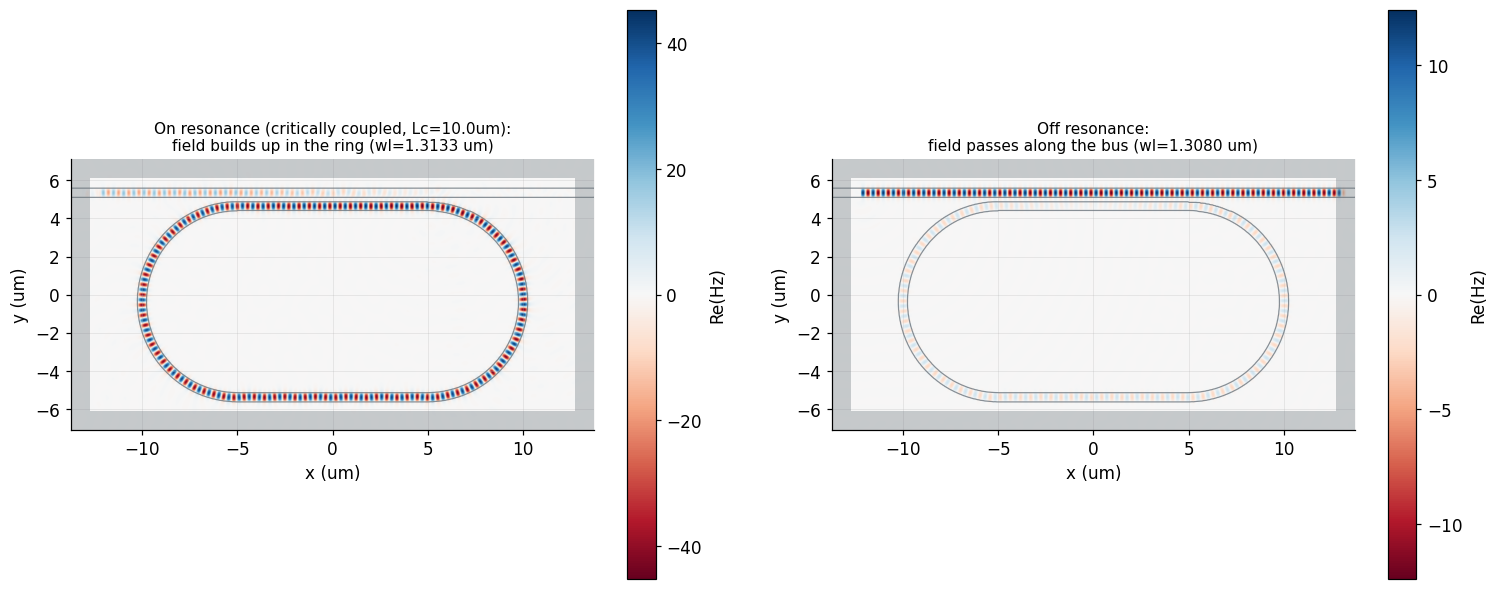

In [16]:
# One extra FDTD run per regime (o1-launched, same as the baseline) that captures Hz at a
# few wavelengths across the resonance plus one clean off-resonance wavelength -- see
# capture_field_snapshots's docstring for why this can't reuse the sweep runs above.
# The dip and the off-resonance point come from each design's fine Section-9 sweep data;
# the on-resonance snapshot is the scanned wavelength with the lowest bus transmission
# measured from the field itself (racetrack.bus_power_ratio). Cached per regime.
REGIME_CACHE = {"under-coupled": "under", "critically coupled": "critical"}


def regime_field_snapshots(name):
    """(on-resonance snapshot, off-resonance snapshot, run params) for one regime."""
    lc = REGIME_LENGTHS[name]
    artifact = artifacts_by_length[lc]
    s21_power = np.abs(artifact.s_matrix["21"]) ** 2
    dip = artifact.wavelengths_um[np.argmin(s21_power)]
    clean = artifact.wavelengths_um[np.argmax(s21_power)]
    run_params = dict(params, coupling_length_um=lc)
    snaps = racetrack.load_or_capture_field_snapshots(
        run_params, racetrack.resonance_scan_wavelengths(dip, clean),
        f"../data/field_cache/racetrack_{REGIME_CACHE[name]}_snapshots.pkl")
    scan, off_resonance = snaps[:-1], snaps[-1]
    on_resonance = min(scan, key=lambda s: racetrack.bus_power_ratio(s, run_params))
    return on_resonance, off_resonance, run_params


regime_snapshots = {name: regime_field_snapshots(name) for name in REGIME_LENGTHS}
for name, (on_res, off_res, run_params) in regime_snapshots.items():
    lc = REGIME_LENGTHS[name]
    print(f"{name:>19} (Lc={lc}um): on resonance wl={on_res.wavelength_um:.5f} um, bus power ratio from the "
          f"field {racetrack.bus_power_ratio(on_res, run_params):.3f} (sweep T_min {cmt_by_length[lc]['T_min']:.3f}); "
          f"off resonance wl={off_res.wavelength_um:.5f} um, ratio {racetrack.bus_power_ratio(off_res, run_params):.3f}")

# Selected (critically coupled) design: on vs off resonance.
on_res, off_res, _ = regime_snapshots["critically coupled"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
titles = [f"On resonance (critically coupled, Lc={SELECTED_COUPLING_LENGTH_UM}um):\nfield builds up in the ring",
          "Off resonance:\nfield passes along the bus"]
for ax, snap, title in zip(axes, (on_res, off_res), titles):
    viz.plot_field(snap.field, snap.eps, snap.extent_um, component=snap.component, ax=ax,
                    pml_um=params["dpml_um"])
    ax.set_title(f"{title} (wl={snap.wavelength_um:.4f} um)", fontsize=10)
fig.tight_layout()
plt.show()


**What a physically reasonable pair of snapshots should show:**
- **Left (on resonance)**: field intensity **built up inside the racetrack** --
  distributed around the whole loop, not just at the coupling section -- and an
  almost dark bus downstream of the coupling region: at critical coupling the light
  coupled back out of the ring cancels the light that passes the coupler, and all of
  the input power is absorbed in the ring.
- **Right (off resonance)**: a clean, regular oscillation pattern **passing straight
  through the bus**, with only a faint evanescent tail bridging the gap into the
  racetrack (no resonant buildup).

The printed bus power ratios should match the swept on-resonance $|S_{21}|^2$ to within
the small reflection; if they do not, the snapshot wavelengths are not where the
sweep found the resonance.

### Under-coupled vs critically coupled, on resonance

The figure below shows the under-coupled ($L_c$ = 4 um) and the critically coupled
($L_c$ = 10 um) ring, each at its own resonance, on one color scale normalized to the
incident bus field:
- **under-coupled** ($t > a$): the ring fills, but the coupler is too weak to let as
  much light out as the ring absorbs, so the light leaking out of the ring cancels only
  part of the light passing the coupler, and a strong field remains in the output bus
  ($|S_{21}| \approx 0.56$).
- **critically coupled** ($t = a$): the output bus goes dark. The light leaking out of
  the ring has the same amplitude as the light passing the coupler and the opposite
  phase.

The bottom panel traces $|H_z|$ along the bus. Downstream of the racetrack it should
settle at $\sqrt{T_{min}}$ from the sweep (dotted lines).

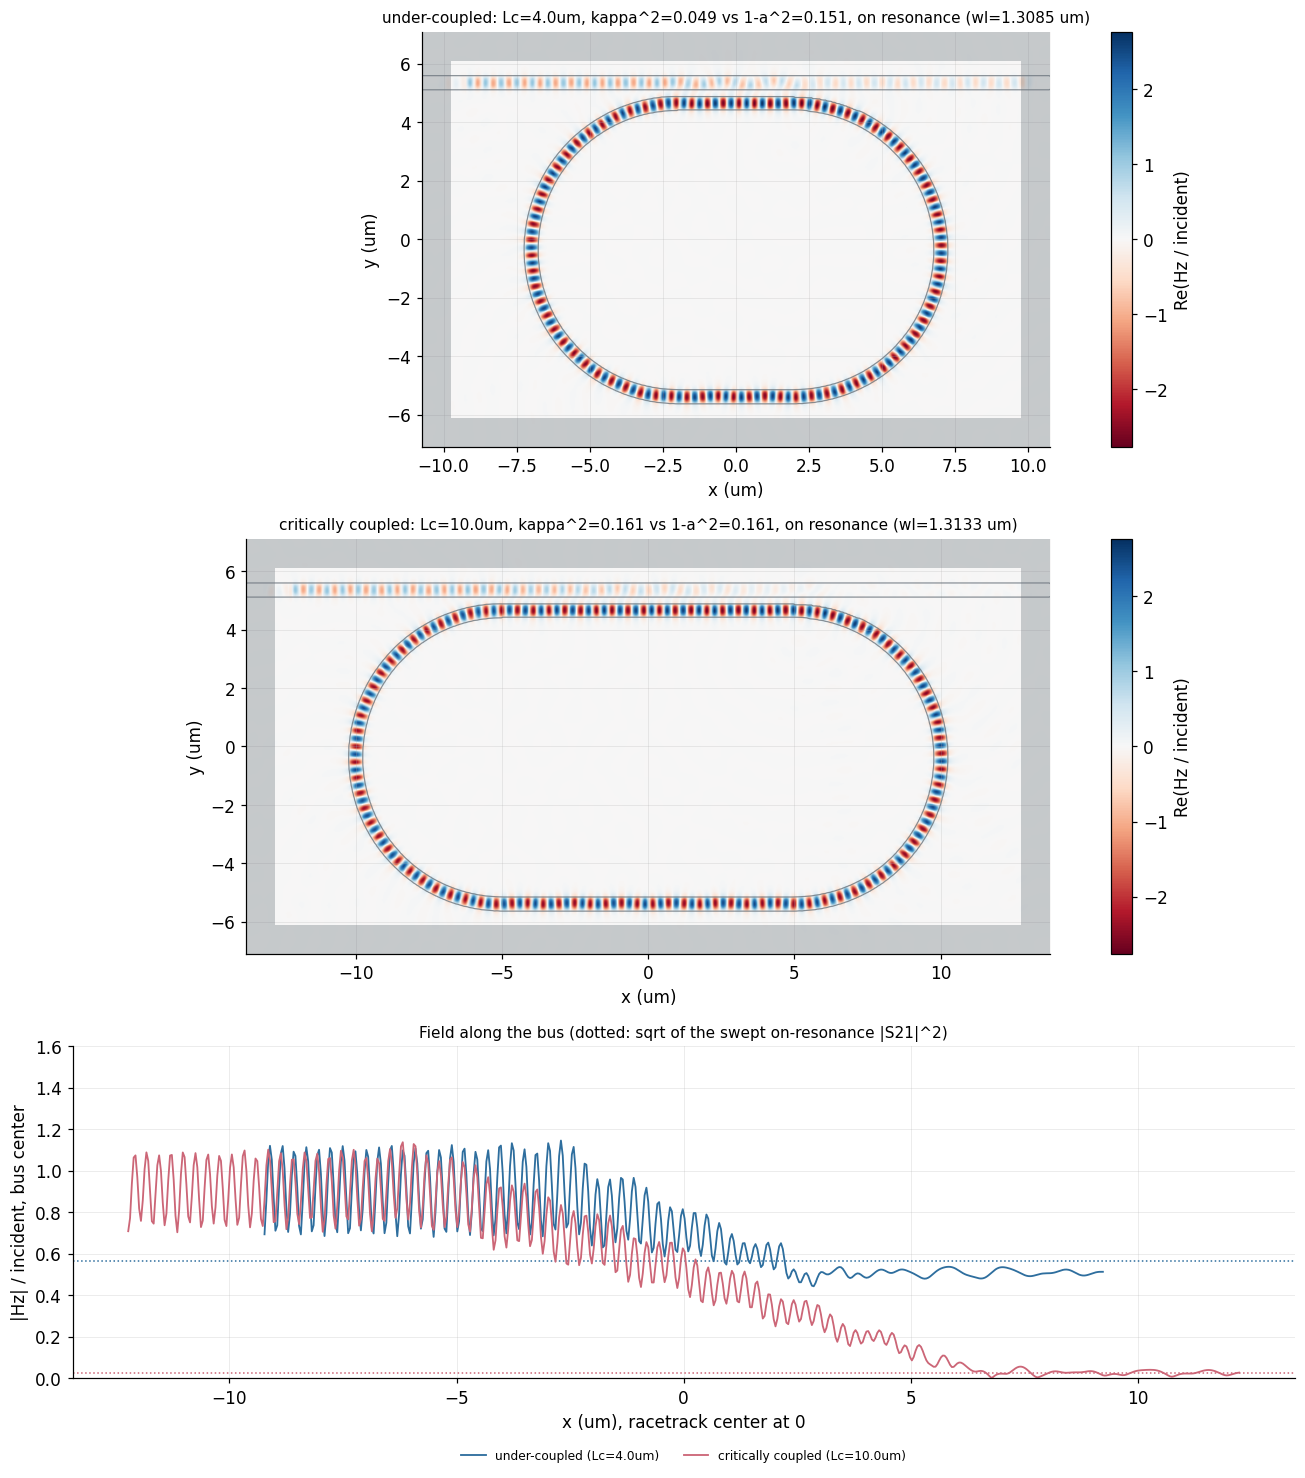

      under-coupled: peak |Hz| in the cell / incident = 2.88
 critically coupled: peak |Hz| in the cell / incident = 2.77


In [17]:
# On-resonance Hz for the under-coupled and the critically coupled ring, on one shared color scale: each field is
# divided by the incident bus amplitude (sqrt(2) x rms over the bus core between the source
# and the racetrack), so ring build-up and the field left in the output bus compare directly.
def incident_amplitude(snap, run_params):
    dom = racetrack._compute_domain(run_params)
    x = np.linspace(snap.extent_um[0], snap.extent_um[1], snap.field.shape[0])
    y = np.linspace(snap.extent_um[2], snap.extent_um[3], snap.field.shape[1])
    upstream = (x > -dom["source_offset"] + 0.2) & (x < -dom["half_length"] - 0.2)
    bus_core = np.abs(y - dom["bus_y"]) < run_params["wg_width_um"] / 2
    return np.sqrt(2 * np.mean(np.abs(snap.field[np.ix_(upstream, bus_core)]) ** 2))


normalized = {name: on_res.field / incident_amplitude(on_res, run_params)
              for name, (on_res, _, run_params) in regime_snapshots.items()}
shared_vmax = max(np.max(np.abs(f.real)) for f in normalized.values())
fig, axes = plt.subplots(3, 1, figsize=(12, 13.5), gridspec_kw={"height_ratios": [1, 1, 0.8]})
regime_line_colors = (style.COLOR_STEEL, style.COLOR_ROSE)
for ax, (name, (on_res, _, run_params)), color in zip(axes, regime_snapshots.items(), regime_line_colors):
    lc = REGIME_LENGTHS[name]
    c = cmt_by_length[lc]
    viz.plot_field(normalized[name], on_res.eps, on_res.extent_um, component="Hz / incident",
                   ax=ax, pml_um=params["dpml_um"], vmax=shared_vmax)
    ax.set_title(f"{name}: Lc={lc}um, kappa^2={c['chosen']['kappa2']:.3f} vs 1-a^2={c['kappa2_crit']:.3f}, "
                 f"on resonance (wl={on_res.wavelength_um:.4f} um)", fontsize=10)

    # |Hz| along the bus core center, x measured from the racetrack center. Downstream of the
    # coupler it should settle at sqrt(T_min) of the sweep (dotted line).
    dom = racetrack._compute_domain(run_params)
    x = np.linspace(on_res.extent_um[0], on_res.extent_um[1], on_res.field.shape[0])
    y = np.linspace(on_res.extent_um[2], on_res.extent_um[3], on_res.field.shape[1])
    keep = np.abs(x) < dom["source_offset"]
    axes[2].plot(x[keep], np.abs(normalized[name][keep, np.argmin(np.abs(y - dom["bus_y"]))]), color=color,
                 lw=1.2, label=f"{name} (Lc={lc}um)")
    axes[2].axhline(np.sqrt(c["T_min"]), color=color, ls=":", lw=1)
axes[2].set_xlabel("x (um), racetrack center at 0"); axes[2].set_ylabel("|Hz| / incident, bus center")
axes[2].set_title("Field along the bus (dotted: sqrt of the swept on-resonance |S21|^2)", fontsize=10)
axes[2].set_ylim(0, 1.6)
axes[2].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
fig.tight_layout()
plt.show()
for name, f in normalized.items():
    print(f"{name:>19}: peak |Hz| in the cell / incident = {np.max(np.abs(f)):.2f}")


> **STOP -- INSPECT THE ELECTROMAGNETIC FIELD BEFORE CONTINUING.**
>
> The output bus must be visibly darker for the critically coupled ring, and its level
> downstream in the line plot should match the dotted $\sqrt{T_{min}}$ for both rings. If a
> ring looks dark on resonance, or the printed bus power ratio disagrees with the
> sweep, the snapshot wavelengths did not land on the resonance -- check the printed
> scan above.

## 12. SAX model fitting

Section 10 already fitted every swept resonance (`cmt_by_length`). This section
compares the chosen-branch model against the FDTD spectrum for every swept point,
shows for the under-coupled Lc = 4 um point why the phase decides the branch, and saves the
selected fit as the model `models/racetrack.py` evaluates:

$$S_{21}(\nu) = \frac{t - a\,e^{j\phi(\nu)}}{1 - t\,a\,e^{j\phi(\nu)}}, \qquad
\phi(\nu) = 2\pi n_g L\,(\nu - \nu_{res}), \qquad L = 2\pi R + 2 L_c, \qquad a = e^{-\alpha L/2}$$

- $t = \sqrt{1-\kappa^2}$ -- bus-ring self-coupling (field) at this `coupling_length_um`;
- $a$, $\alpha$ -- single-pass transmission and power attenuation per um of the ring;
- $n_g$ -- group index from the Section 6 free spectral range; $\nu_{res} = 1/\lambda_{res}$ --
  fitted resonance frequency. $n_{eff}$ is not a parameter: one resonance does not determine it.

Passivity ($|S_{21}| \le 1$) holds by construction since $t, a \in [0, 1]$.

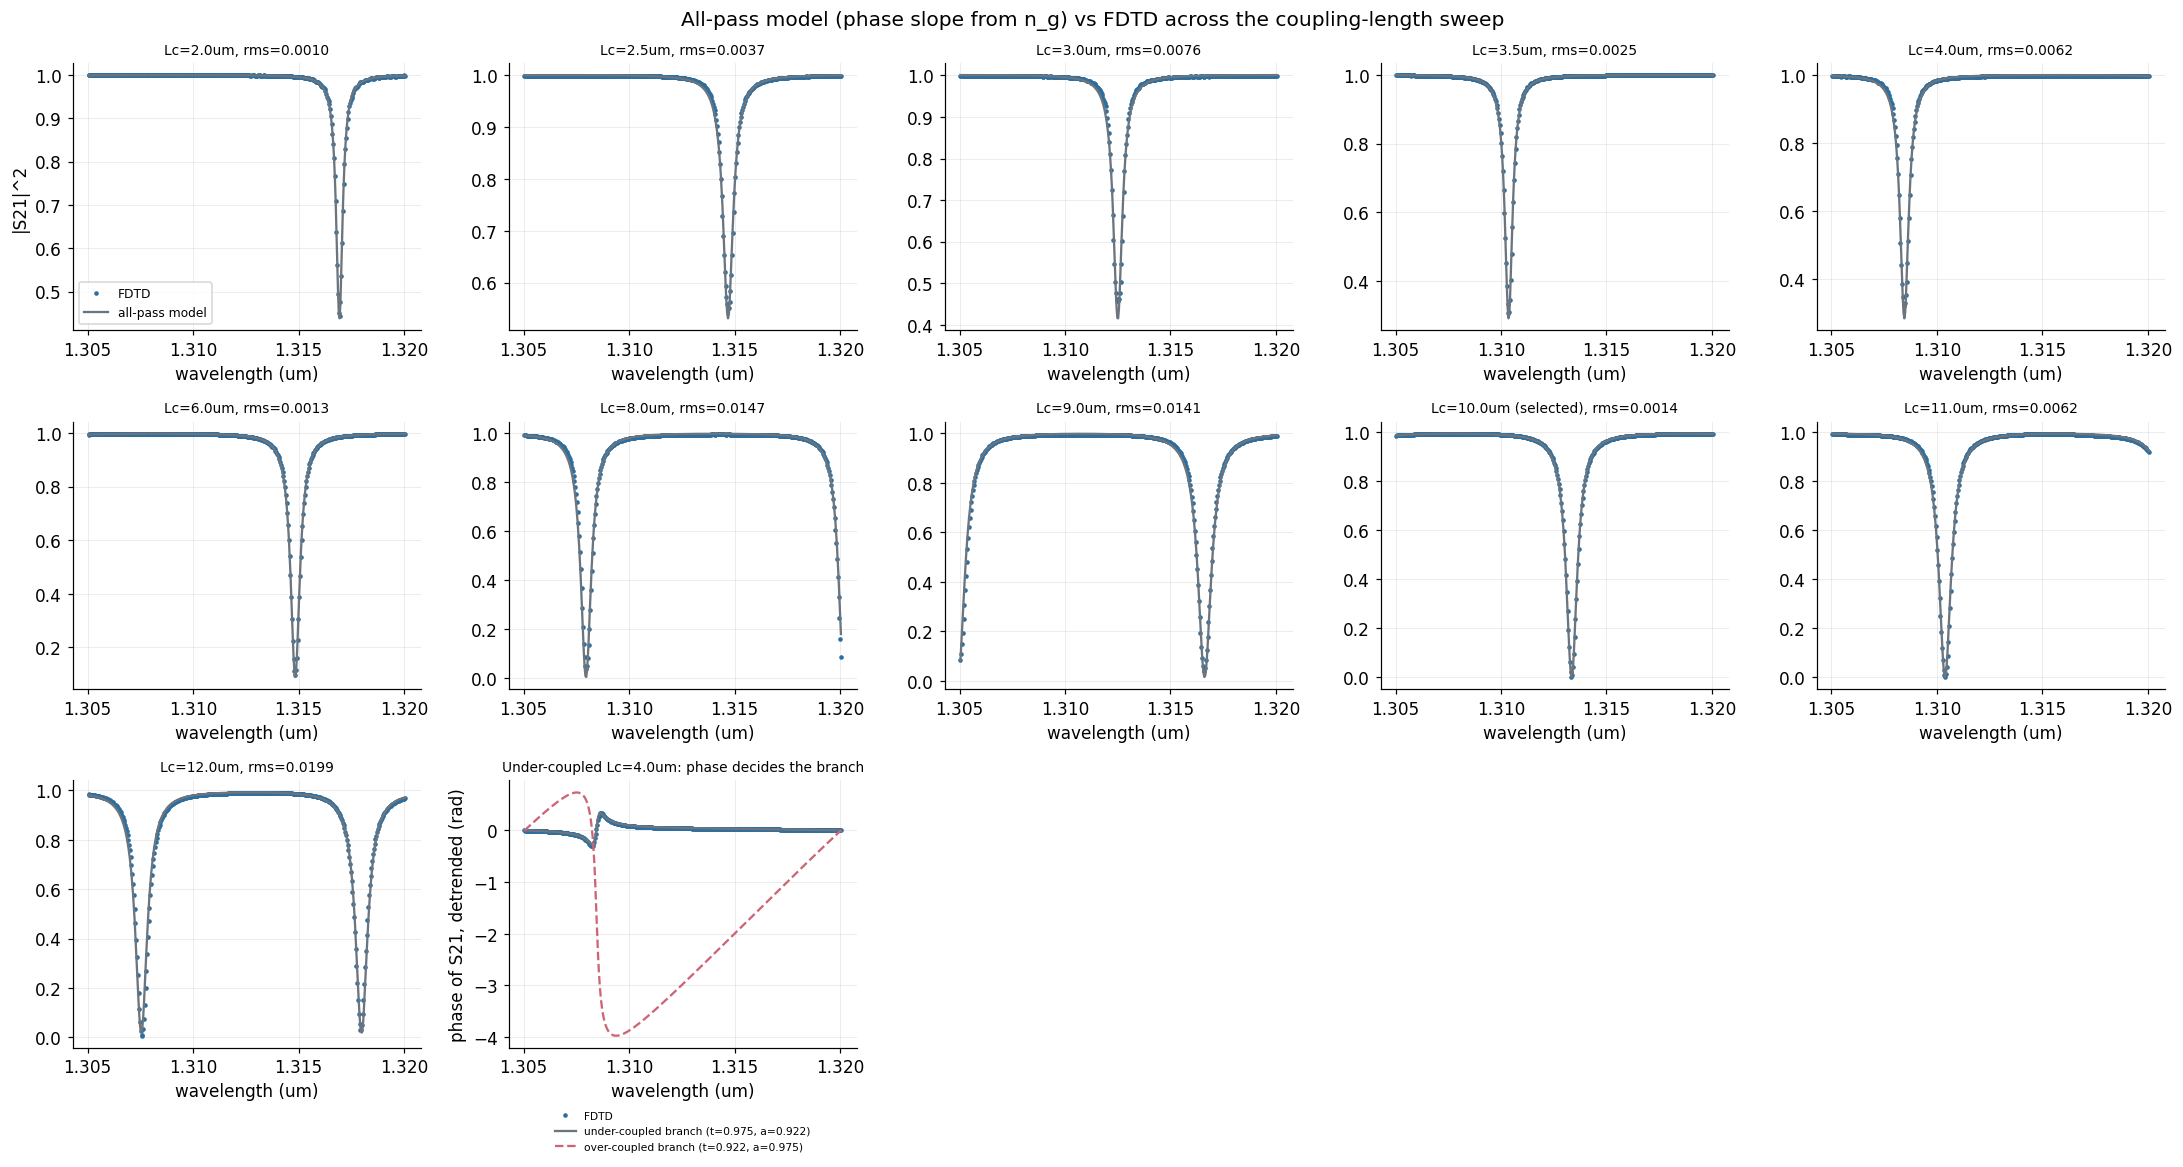

Selected: coupling_length_um=10.0  regime=critically coupled  kappa=0.4010  t=0.9161  a=0.9161  alpha=3.409e-03 1/um  n_g=2.978  lambda_res=1.31335 um
FWHM measured 0.599 nm vs formula 0.629 nm;  Q_L=2191, Q_i=4179, Q_c=4608;  fit rms=0.0014
measured phase swing 4.85 rad >= pi -> over-coupled; |t - a| = 0.0000 < 0.005 -> critically coupled (both branches coincide)


In [18]:
# Chosen-branch model vs FDTD for every swept point (power), plus the selected
# point's phase, where the two t<->a branches differ.
N_COLS = 5
n_rows = int(np.ceil((len(COUPLING_LENGTH_SWEEP_UM) + 1) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(4 * N_COLS, 3.6 * n_rows))
axes = axes.ravel()
for ax in axes[len(COUPLING_LENGTH_SWEEP_UM) + 1:]:
    ax.set_visible(False)
for ax, lc in zip(axes, COUPLING_LENGTH_SWEEP_UM):
    f, c = cmt_by_length[lc], cmt_by_length[lc]["chosen"]
    a_lc = artifacts_by_length[lc]
    nu = 1 / a_lc.wavelengths_um
    model = ring_fit.all_pass(nu, c["t"], c["a"], 1 / c["lambda_res_um"], 1 / (N_G * f["L_um"]), c["scale"])
    ax.plot(a_lc.wavelengths_um, np.abs(a_lc.s_matrix["21"]) ** 2, "o", ms=2, color=style.COLOR_STEEL, label="FDTD")
    ax.plot(a_lc.wavelengths_um, np.abs(model) ** 2, "-", color=style.COLOR_REFERENCE, label="all-pass model")
    tag = " (selected)" if lc == SELECTED_COUPLING_LENGTH_UM else ""
    ax.set_title(f"Lc={lc}um{tag}, rms={c['rms']:.4f}", fontsize=9)
    ax.set_xlabel("wavelength (um)")
axes[0].set_ylabel("|S21|^2")
axes[0].legend(fontsize=8)

# Phase of the under-coupled resonance: data vs both branches (at the selected, critically
# coupled point the two branches nearly coincide, so the phase cannot separate them there).
f_sel = cmt_by_length[UNDER_COUPLING_LENGTH_UM]
a_sel = artifacts_by_length[UNDER_COUPLING_LENGTH_UM]
# detrended_phase returns values in the order of its wavelength argument; the models are
# evaluated on a sorted grid so their curves draw as lines.
wl_sorted = np.sort(a_sel.wavelengths_um)
ax = axes[len(COUPLING_LENGTH_SWEEP_UM)]
ax.plot(a_sel.wavelengths_um, ring_fit.detrended_phase(a_sel.wavelengths_um, a_sel.s_matrix["21"]), "o", ms=2,
        color=style.COLOR_STEEL, label="FDTD")
for name, ls, col in (("under", "-", style.COLOR_REFERENCE), ("over", "--", style.COLOR_ROSE)):
    b = f_sel["branches"][name]
    m = ring_fit.all_pass(1 / wl_sorted, b["t"], b["a"], 1 / b["lambda_res_um"], 1 / (N_G * f_sel["L_um"]), b["scale"])
    ax.plot(wl_sorted, ring_fit.detrended_phase(wl_sorted, m), ls, color=col,
            label=f"{name}-coupled branch (t={b['t']:.3f}, a={b['a']:.3f})")
ax.set_title(f"Under-coupled Lc={UNDER_COUPLING_LENGTH_UM}um: phase decides the branch", fontsize=9)
ax.set_xlabel("wavelength (um)"); ax.set_ylabel("phase of S21, detrended (rad)")
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)  # below the axes, off the curves
fig.suptitle("All-pass model (phase slope from n_g) vs FDTD across the coupling-length sweep")
fig.tight_layout()
plt.show()

FIT_COUPLING_LENGTH_UM = SELECTED_COUPLING_LENGTH_UM
cmt_fit = cmt_by_length[FIT_COUPLING_LENGTH_UM]["chosen"]
print(f"Selected: coupling_length_um={FIT_COUPLING_LENGTH_UM}  regime={cmt_fit['regime']}  "
      f"kappa={cmt_fit['kappa']:.4f}  t={cmt_fit['t']:.4f}  a={cmt_fit['a']:.4f}  "
      f"alpha={cmt_fit['alpha_per_um']:.3e} 1/um  n_g={N_G:.3f}  lambda_res={cmt_fit['lambda_res_um']:.5f} um")
print(f"FWHM measured {cmt_by_length[FIT_COUPLING_LENGTH_UM]['fwhm_nm']:.3f} nm vs formula "
      f"{cmt_fit['fwhm_formula_nm']:.3f} nm;  Q_L={cmt_by_length[FIT_COUPLING_LENGTH_UM]['Q_L']:.0f}, "
      f"Q_i={cmt_fit['Q_i']:.0f}, Q_c={cmt_fit['Q_c']:.0f};  fit rms={cmt_fit['rms']:.4f}")
print(cmt_by_length[FIT_COUPLING_LENGTH_UM]["reason"])

> **STOP -- inspect the fit before saving.**
>
> Each power panel's model curve should sit on that point's FDTD markers, including at
> the dip. In the phase panel (the under-coupled $L_c$ = 4 um point) the FDTD points must
> follow the under-coupled branch only: a small swing that returns, not a $2\pi$ step.
> At the selected, critically coupled point the two branches nearly coincide
> ($t \approx a$), so its fit is checked by its power panel and by $T_{min} \approx 0$.
> If the points follow neither branch, the resonance is under-resolved or the phase
> slope ($n_g$, Section 6) is off.

In [19]:
# Add the fitted model to the design point -- a single YAML file remains the sole
# source of truth for this component's parameters + model.
existing_design_point = design_points.load_design_point(design_point_path)
existing_design_point["fitted_model"] = {
    "radius_um": params["radius_um"],
    "coupling_length_um": FIT_COUPLING_LENGTH_UM,
    "t": cmt_fit["t"],
    "kappa": cmt_fit["kappa"],
    "a": cmt_fit["a"],
    "alpha": cmt_fit["alpha_per_um"],
    "n_g": float(N_G),
    "lambda_res_um": cmt_fit["lambda_res_um"],
    "regime": cmt_fit["regime"],
    "branch_reason": cmt_by_length[FIT_COUPLING_LENGTH_UM]["reason"],
    "fit_method": (
        "all-pass coupling-matrix model fitted to the narrowband FDTD resonance (least squares on "
        "|S21|^2, free t, a, resonance frequency and a near-unity scale), with the round-trip phase "
        "linearized by the group index measured from the full-band free spectral range (Section 6). "
        "Both t<->a branches fitted; the branch is chosen from the measured S21 phase swing and the "
        "conductivity absorption floor (Section 10). See pic_toolkit.ring_fit."
    ),
    "fit_residual_rms": cmt_fit["rms"],
}
design_points.save_design_point(design_point_path, existing_design_point)
print(f"Updated design point with fitted_model: {design_point_path}")

Updated design point with fitted_model: ../data/design_points/racetrack.yaml


## 13. Racetrack SAX model

`src/pic_toolkit/models/racetrack.py` is the reusable component built from the design
point saved above, including Section 12's `fitted_model` -- valid at the one
`coupling_length_um` selected in Section 10 (not evaluable at other lengths; see
Section 12 for the model). **It is not exercised in this notebook** -- this notebook
already imports meep, and the whole point of the SAX model is that it must work in a
process that never has -- so it should be verified separately, in a clean, meep-free
process (the same approach every other component uses).


In [20]:
with open("../../src/pic_toolkit/models/racetrack.py") as f:
    print(f.read())

"""SAX-compatible component model for the all-pass racetrack resonator.

Architectural rule: this file NEVER imports meep, and NEVER launches an FDTD
simulation. It evaluates the all-pass coupling-matrix model of a ring coupled to
one bus (Yariv, Electron. Lett. 36, 321 (2000); Bogaerts et al., Laser Photonics
Rev. 6, 47 (2012)) with the parameters `05_racetrack_resonator.ipynb` fitted to
one finely resolved FDTD resonance (`pic_toolkit.ring_fit.fit_all_pass` /
`choose_branch`) at the one `coupling_length_um` the notebook selected. Unlike
`models/waveguide.py`/`models/bend.py`, it does NOT generalize to other
`coupling_length_um` values.

Independent of the since-removed models/ring.py -- this is a different
component (`racetrack`, not `ring`).
"""

from __future__ import annotations

import sys
from pathlib import Path

import numpy as np

from .. import design_points, ring_fit, sparams

assert "meep" not in sys.modules, "pic_toolkit.models.racetrack must never coexist with a meep imp

---

## 14. Summary

Baseline validated (built from GDSFactory-derived geometry, Section 3), an 11-point
coupling-length sweep from 2 to 12 um performed with the gap fixed at an easily resolved
200 nm, and a design point selected and saved. One point carries forward for any resonant
device (Section 7): the generic 2-port `checks.energy_conservation_check` is the wrong
tool for a resonator, which is SUPPOSED to absorb strongly at resonance.
`racetrack.energy_conservation_check` applies a tight off-resonance / loose on-resonance
split instead.

The resonance fits (Sections 6, 10, 12) use the group index measured from the free
spectral range for the round-trip phase, fit both $t \leftrightarrow a$ branches, and
choose the physical one from the $S_{21}$ phase and the absorption floor. The short
racetracks are under-coupled; the sweep reaches **critical coupling at $L_c$ = 10 um**
($t = a = 0.916$, on-resonance $|S_{21}|^2 \approx 0.001$, the saved design point) and
just passes it at 12 um. Because $L_c$ also lengthens the ring, the round-trip loss grows
with the coupling and the ring stays near critical coupling over several micrometers.
Section 11 compares the two regimes in the field: light left in the output bus
(under-coupled) and a dark output bus (critically coupled). The selected fit is loaded in any
meep-free process via `from pic_toolkit.models.racetrack import racetrack`, at the one
`coupling_length_um` selected here.